In [1]:
from math import erf, sqrt
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf
import warnings

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
RAW.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

DATA_START = "2016-01-01"  # a few extra months before the backtest, for rolling windows to warm up
START = "2016-10-24"       # backtest window: 10 years
END = "2026-10-23"

universe = pd.read_csv(ROOT / "data" / "universe" / "universe_v1.csv")
SYMBOLS = universe["yahoo_symbol"].tolist()
SYMBOLS

['OHLA.MC',
 'EDR.MC',
 'AMP.MC',
 'ORY.MC',
 'TUB.MC',
 'ENC.MC',
 'NXT.MC',
 'DOM.MC',
 'GSJ.MC',
 'ADX.MC']

In [2]:
def load_raw(symbol):
    path = RAW / f"{symbol}.csv"
    if not path.exists():
        h = yf.Ticker(symbol).history(period="max", auto_adjust=False, actions=True)
        h.index = h.index.tz_localize(None)  # keep the dates, drop the Madrid timezone
        h.to_csv(path)
    return pd.read_csv(path, index_col="Date", parse_dates=True)


raw = {s: load_raw(s) for s in SYMBOLS}
raw["OHLA.MC"].tail(3)

,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
Date,,,,,,,,
2026-10-21,0.3390,0.3428,0.3366,0.3400,0.3400,3948871,0.0,0.0
2026-10-22,0.3400,0.3400,0.3270,0.3276,0.3276,5426905,0.0,0.0
2026-10-23,0.3276,0.3336,0.3272,0.3300,0.3300,4816717,0.0,0.0


Things that go wrong with daily price data, and how to spot each one:

| Problem | Check |
|---|---|
| Days with no trading (holidays, suspensions) | `Volume == 0` |
| Impossible bars | High below the open or close, or Low above them |
| Splits the provider missed | a huge overnight gap with no split recorded |
| Dividends | counted here; `Adj Close` already accounts for them |

In [3]:
def quality_report(h):
    h = h.loc[START:END]
    top = h[["Open", "Close"]].max(axis=1)
    bottom = h[["Open", "Close"]].min(axis=1)
    overnight_gap = h["Open"] / h["Close"].shift(1) - 1
    return {
        "days": len(h),
        "zero_volume_days": int((h["Volume"] == 0).sum()),
        # tiny tolerance: prices are floats, so equal values can differ in the last digit
        "bad_high_low": int(((h["High"] < top - 1e-9) | (h["Low"] > bottom + 1e-9)).sum()),
        "dividends": int((h["Dividends"] > 0).sum()),
        "splits_recorded": int((h["Stock Splits"] > 0).sum()),
        "worst_overnight_gap": round(overnight_gap.min(), 3),
        "worst_gap_date": overnight_gap.idxmin().date(),
    }


report = pd.DataFrame({s: quality_report(h) for s, h in raw.items()}).T
report

,days,zero_volume_days,bad_high_low,dividends,splits_recorded,worst_overnight_gap,worst_gap_date
OHLA.MC,2558,1,0,0,0,-0.132,2018-11-15
EDR.MC,2558,1,1,0,0,-0.242,2025-11-19
AMP.MC,2558,1,0,0,1,-0.132,2020-03-09
ORY.MC,2558,2,1,0,0,-0.17,2025-04-24
TUB.MC,2558,1,0,6,0,-0.059,2016-11-09
ENC.MC,2558,1,0,16,0,-0.096,2020-03-12
NXT.MC,2558,4,4,0,0,-0.73,2018-08-03
DOM.MC,2558,1,1,7,0,-0.061,2020-08-14
GSJ.MC,2558,2,0,7,0,-0.108,2020-03-09
ADX.MC,2558,1,0,4,0,-0.125,2020-03-12


### Finding 1 · A phantom Christmas day

Every stock has a zero-volume row on 25 Dec 2019, when the exchange was closed. Yahoo just copied the previous price forward. A few other zero-volume days are real days with no trades. Either way there's no real price that day, so we drop those rows.

In [5]:
{s: [str(d.date()) for d in h.loc[START:END].index[h.loc[START:END, "Volume"] == 0]] for s, h in raw.items()}

{'OHLA.MC': ['2019-12-25'],
 'EDR.MC': ['2019-12-25'],
 'AMP.MC': ['2019-12-25'],
 'ORY.MC': ['2016-11-03', '2019-12-25'],
 'TUB.MC': ['2019-12-25'],
 'ENC.MC': ['2019-12-25'],
 'NXT.MC': ['2019-12-25', '2020-07-31', '2022-05-05', '2022-09-07'],
 'DOM.MC': ['2019-12-25'],
 'GSJ.MC': ['2019-12-25', '2023-08-28'],
 'ADX.MC': ['2019-12-25']}

### Finding 2 · Nextil's −73% day is a split Yahoo missed

On 3 Aug 2018 Nextil's price falls from €3.63 to €0.88 overnight, and volume jumps about 5×. That pattern (price ÷ ~4, volume × ~4) is the signature of a split. Nextil split each share into 4 that day, when it also changed its ticker from DGI to NXT ([Europa Press via Bolsamanía](https://www.bolsamania.com/noticias/empresas/economiaempresas--nextil-nueva-expresion-textil-formaliza-un-split-de-cuatro-nuevas-acciones-por-cada-una-antigua--3427338.html)), but Yahoo has no split recorded.

**Why this matters:** left in, this would be the biggest "dip" in the whole dataset, and the strategy would buy it.

In [4]:
raw["NXT.MC"].loc["2018-07-31":"2018-08-07", ["Open", "High", "Low", "Close", "Volume", "Stock Splits"]]

,Open,High,Low,Close,Volume,Stock Splits
Date,,,,,,
2018-07-31,3.765250,3.824545,3.701013,3.701013,9027,0.0
2018-08-01,3.681248,3.730661,3.572540,3.730661,20074,0.0
2018-08-02,3.651600,3.755367,3.626894,3.626894,17077,0.0
2018-08-03,0.978372,0.978372,0.880534,0.881523,96410,0.0
2018-08-06,0.897335,0.897335,0.832110,0.841004,215261,0.0
2018-08-07,0.843969,0.868675,0.840016,0.865711,70377,0.0


### Finding 3 · Amper's reverse split *was* handled

Amper merged every 25 shares into 1 on 20 Jul 2026 (`Stock Splits = 0.04` = 1/25). The prices on either side line up, so Yahoo has already rescaled the history before it. Nothing to fix. Checking a split that was handled is how you learn what a missed one looks like.

In [6]:
raw["AMP.MC"].loc["2026-07-16":"2026-07-22", ["Close", "Volume", "Stock Splits"]]

,Close,Volume,Stock Splits
Date,,,
2026-07-16,5.2875,242867,0.00
2026-07-17,5.1750,444314,0.00
2026-07-20,5.1810,145529,0.04
2026-07-21,5.0000,473651,0.00
2026-07-22,5.0000,324316,0.00


### Finding 4 · A few impossible bars

A handful of days have a High below the close, or a Low above the open. Those are data errors. We repair them by setting High to the largest of open, high and close, and Low to the smallest. The rolling VWAP will use the day's average of high, low and close, so these bars matter.

### Not a data error · eDreams, Nov 2025

eDreams opened 24% lower on 19 Nov 2025 and closed 41% down. That's real: the company cut its cash EBITDA forecast for fiscal 2026 by €60m, and the stock lost about half its value that week ([Forbes](https://forbes.es/economia/880598/edreams-vuela-casi-un-20-en-bolsa-tras-multiplicar-por-diez-su-beneficio-neto-en-sus-primeros-nueve-meses/)).

In [9]:
# splits Yahoo missed: (first day at the new share count, new shares per old share)
MISSED_SPLITS = {"NXT.MC": [("2018-08-03", 4)]}
PRICE_COLS = ["Open", "High", "Low", "Close", "Adj Close"]


def clean(symbol, h):
    h = h.loc[DATA_START:END].copy()
    for date, ratio in MISSED_SPLITS.get(symbol, []):
        before = h.index < date
        h.loc[before, PRICE_COLS] /= ratio
        h.loc[before, "Volume"] *= ratio
    h = h[h["Volume"] > 0]  # no trades means no real price that day
    h["High"] = h[["Open", "High", "Close"]].max(axis=1)
    h["Low"] = h[["Open", "Low", "Close"]].min(axis=1)
    return h


data = {s: clean(s, h) for s, h in raw.items()}
for s, h in data.items():
    h.to_csv(PROCESSED / f"{s}.csv")

# Nextil after the fix: no more cliff
data["NXT.MC"].loc["2018-07-31":"2018-08-07", ["Close", "Volume"]]

,Close,Volume
Date,,
2018-07-31,0.925253,36108
2018-08-01,0.932665,80296
2018-08-02,0.906723,68308
2018-08-03,0.881523,96410
2018-08-06,0.841004,215261
2018-08-07,0.865711,70377


In [10]:
# re-run the checks on the cleaned data: these columns should now be zero
pd.DataFrame({s: quality_report(h) for s, h in data.items()}).T[["zero_volume_days", "bad_high_low", "worst_overnight_gap", "worst_gap_date"]]

,zero_volume_days,bad_high_low,worst_overnight_gap,worst_gap_date
OHLA.MC,0,0,-0.132,2018-11-15
EDR.MC,0,0,-0.242,2025-11-19
AMP.MC,0,0,-0.132,2020-03-09
ORY.MC,0,0,-0.17,2025-04-24
TUB.MC,0,0,-0.059,2016-11-09
ENC.MC,0,0,-0.096,2020-03-12
NXT.MC,0,0,-0.088,2016-11-09
DOM.MC,0,0,-0.061,2020-08-14
GSJ.MC,0,0,-0.108,2020-03-09
ADX.MC,0,0,-0.125,2020-03-12


In [11]:
returns = pd.DataFrame({s: h["Adj Close"].loc[START:END].pct_change() for s, h in data.items()})


def normal_below(k):
    """Share of a normal distribution more than k standard deviations below its mean."""
    return 0.5 * (1 + erf(-k / sqrt(2)))


def tail_stats(r):
    r = r.dropna()
    z = (r - r.mean()) / r.std()  # how many standard deviations each day was from the average day
    return {
        "daily_sd_%": 100 * r.std(),
        "annual_vol_%": 100 * r.std() * np.sqrt(252),
        "within_1sd_%": 100 * (z.abs() < 1).mean(),
        "below_-2sd_%": 100 * (z < -2).mean(),
        "below_-3sd_%": 100 * (z < -3).mean(),
        "worst_day_%": 100 * r.min(),
    }


tails = pd.DataFrame({s: tail_stats(returns[s]) for s in SYMBOLS}).T
tails.loc["average of the 10"] = tails.mean()
tails.loc["normal distribution"] = pd.Series({
    "within_1sd_%": 100 * (1 - 2 * normal_below(1)),
    "below_-2sd_%": 100 * normal_below(2),
    "below_-3sd_%": 100 * normal_below(3),
})
tails.round(2)

,daily_sd_%,annual_vol_%,within_1sd_%,below_-2sd_%,below_-3sd_%,worst_day_%
OHLA.MC,3.74,59.43,82.55,1.84,0.63,-23.88
EDR.MC,3.10,49.16,81.96,1.76,0.63,-41.27
AMP.MC,2.90,46.04,80.59,1.72,0.55,-23.38
ORY.MC,3.61,57.28,84.93,1.10,0.39,-27.46
TUB.MC,2.23,35.34,76.21,1.96,0.47,-12.50
ENC.MC,2.31,36.70,76.45,2.39,0.51,-18.93
NXT.MC,2.58,40.95,79.36,1.37,0.31,-28.10
DOM.MC,1.69,26.83,73.36,2.27,0.43,-10.91
GSJ.MC,2.78,44.08,82.35,1.21,0.55,-20.22
ADX.MC,3.36,53.36,85.45,1.06,0.39,-30.21


**Annual volatility** is daily σ × √252. Over independent days the *variance* adds up, so over 252 trading days it's 252× the daily variance, and σ (its square root) is √252 ≈ 15.9× the daily σ. For comparison, the IBEX 35 index usually runs around 15–25% a year, so these stocks are about two to three times as jumpy.

The chart pools every day from all 10 stocks, each measured in its own standard deviations, and compares the shape with a normal distribution. The y-axis is logarithmic (each gridline is 10× the one below), otherwise the tails would be invisible. 22 days fall beyond ±8σ and are off the chart. The most extreme is eDreams' −41% day, about −13σ. Under a normal distribution, a single −8σ day would be expected roughly once in 10^15 days, far longer than the age of the universe.

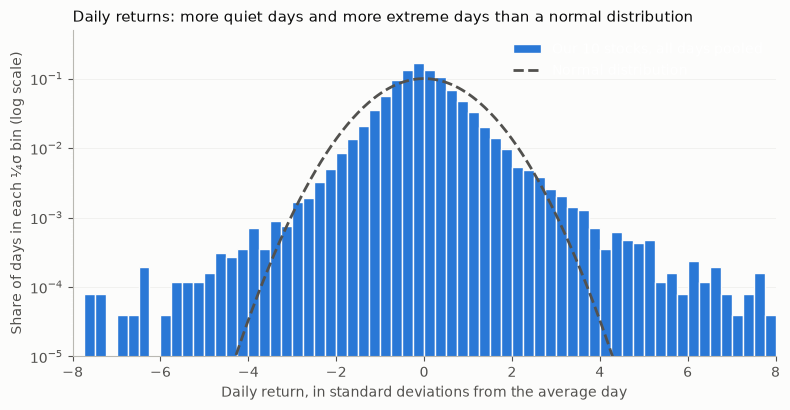

In [12]:
z_all = pd.concat([(returns[s] - returns[s].mean()) / returns[s].std() for s in SYMBOLS]).dropna()
bins = np.arange(-8, 8.25, 0.25)
x = np.linspace(-8, 8, 400)
normal_pdf = np.exp(-x**2 / 2) / np.sqrt(2 * np.pi)
bin_width = 0.25
weights = np.ones(len(z_all)) / len(z_all)  # each day counts as 1/N, so bars show the share of days

fig, ax = plt.subplots(figsize=(8, 4.2), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
ax.hist(z_all, bins=bins, weights=weights, color="#2a78d6", edgecolor="#fcfcfb", linewidth=1,
        label="Our 10 stocks, all days pooled")
ax.plot(x, normal_pdf * bin_width, color="#52514e", linewidth=2, linestyle="--", label="Normal distribution")
ax.set_yscale("log")
ax.set_ylim(1e-5, 0.5)
ax.set_xlim(-8, 8)
ax.set_xlabel("Daily return, in standard deviations from the average day", color="#52514e")
ax.set_ylabel("Share of days in each ¼σ bin (log scale)", color="#52514e")
ax.set_title("Daily returns: more quiet days and more extreme days than a normal distribution",
             loc="left", fontsize=11, color="#0b0b0b")
ax.grid(axis="y", color="#e4e3df", linewidth=0.6)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color("#b9b8b2")
ax.tick_params(colors="#52514e")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

## Part D · One σ for ten years is the wrong yardstick

Volatility comes in **clusters**: calm years, then a crash where every day is huge (March 2020). With one σ for the whole decade, a −2σ day is very rare in a calm year and an everyday event in a crash. That's not the same signal at all.

The fix is to measure each day against a σ computed from the **previous 60 trading days only**. `.shift(1)` moves the σ forward one day, so today's σ is built from data up to yesterday. Without it, today's own return would be part of the yardstick it's measured against: a big drop would inflate its own σ and shrink its own z-score. (Strictly, that isn't look-ahead, since today's return is known at the close. The real look-ahead in this notebook is the "one σ for 10 years" row, which judges 2017 using a σ that includes 2020's crash.)

The returns for this part start at `DATA_START`, so the first 60-day window is already full on the first backtest day. That's why we downloaded a few extra months.

(Here `z` is today's return ÷ the past σ. The average daily return is close to zero, so subtracting it changes almost nothing.)

In [13]:
def rolling_z(prices, window=60):
    # start from DATA_START so the first window is already full on START
    r = prices.pct_change().dropna()
    past_sd = r.rolling(window).std().shift(1)
    return (r / past_sd).loc[START:END]


z_full = pd.DataFrame({s: (returns[s] - returns[s].mean()) / returns[s].std() for s in SYMBOLS})
z_roll = pd.DataFrame({s: rolling_z(h["Adj Close"]) for s, h in data.items()})

comparison = pd.DataFrame({
    "below_-2sd_%": [100 * (z_full < -2).sum().sum() / z_full.notna().sum().sum(),
                     100 * (z_roll < -2).sum().sum() / z_roll.notna().sum().sum(),
                     100 * normal_below(2)],
    "below_-3sd_%": [100 * (z_full < -3).sum().sum() / z_full.notna().sum().sum(),
                     100 * (z_roll < -3).sum().sum() / z_roll.notna().sum().sum(),
                     100 * normal_below(3)],
}, index=["one σ for 10 years", "σ of the past 60 days", "normal distribution"])
comparison.round(2)

,below_-2sd_%,below_-3sd_%
one σ for 10 years,1.67,0.49
σ of the past 60 days,2.24,0.73
normal distribution,2.28,0.13


In [14]:
# how many -2σ days per year, across all 10 stocks, under each yardstick
per_year = pd.DataFrame({
    "one σ for 10 years": (z_full < -2).groupby(z_full.index.year).sum().sum(axis=1),
    "σ of the past 60 days": (z_roll < -2).groupby(z_roll.index.year).sum().sum(axis=1),
})
per_year

,one σ for 10 years,σ of the past 60 days
Date,,
2016,12,8
2017,38,52
2018,64,73
2019,31,40
2020,110,71
2021,34,47
2022,43,65
2023,18,50
2024,13,56


### Drops arrive together

When the whole market falls, several of our stocks have a −2σ day at once. Trades on the same day aren't independent bets: they're partly one bet on "the market bounces". This matters later, when we ask whether the results could be luck.

In [15]:
drops = z_roll < -2
stocks_dropping = drops.sum(axis=1)
print("days with a -2σ drop in 3+ stocks at once:", int((stocks_dropping >= 3).sum()))
print("share of all -2σ drops that happened on those days: %.0f%%"
      % (100 * drops[stocks_dropping >= 3].sum().sum() / drops.sum().sum()))
print("average correlation between two of our stocks' daily returns: %.2f"
      % ((returns.corr().values.sum() - len(SYMBOLS)) / (len(SYMBOLS) * (len(SYMBOLS) - 1))))

days with a -2σ drop in 3+ stocks at once: 33
share of all -2σ drops that happened on those days: 25%
average correlation between two of our stocks' daily returns: 0.17


## Takeaways for the strategy

1. **The data needed fixing.** A missed split, a phantom holiday and a few impossible bars. The cleaned files in `data/processed/` are what every later notebook uses.
2. **Returns aren't normal.** Compared with a normal distribution, there are more quiet days and more extreme days, and fewer in between. A −3σ day happens several times more often than the normal distribution says.
3. **The yardstick must be local and past-only.** σ must come from recent data (volatility clusters), must not include the day being judged (`.shift(1)`), and must never use future days (the full-decade σ does, which is look-ahead). The signal in notebook 03 will follow both rules.
4. **Drops cluster.** A good share of signals will land on market-wide sell-off days, so the trades aren't fully independent bets.